# Bugs found in FractalIntegrals.jl

**Status: A to J in section 5 are now fixed** (see `dev_notes/changes_to_existing_code.md`). This is a record of the bugs: the outputs below come from commit `6d469dd`, before any fixes, on Julia 1.12. Every cell calls the real code in `src/`, so re-running it now will show different output.

Start with sections 1 to 3, the three findings Andrew queried. Section 4 has the rest and section 5 is the list to approve.

In [1]:
using Pkg
Pkg.activate(joinpath(@__DIR__, "..", ".."); io = devnull)
using FractalIntegrals, LinearAlgebra, Plots
const F = FractalIntegrals

# run f and print its result, or the error it throws
function attempt(name, f)
    result = try
        string(f())
    catch e
        "THROWS " * first(sprint(showerror, e), 150)
    end
    println(rpad(name, 48), " => ", result)
end
dust = getfractal("cantordust");

## 1. `∪` and block operators

**Verdict: this is a real bug, and also a regression, so block operators did work when Andrew checked them.**

This is the minimal example, taken from Andrew's own `debug/block_test.jl`:

In [2]:
Γ₁ = getfractal("cantor dust")
Γ₂ = getfractal("cantor set") + 1.5
try
    F.singlelayer_operator_helmholtz((Γ₁, Γ₂), 2.0)
catch e
    showerror(stdout, e)
end

MethodError: no method matching 

∪(::HausdorffMeasure{2, 4, Float64, FractalIntegrals.HomogenousAttractor{2, 4, Float64}}, ::HausdorffMeasure{2, 2, Float64, FractalIntegrals.HomogenousAttractor{2, 2, Float64}})
You may have intended to import Base.

:∪
The function `∪` exists, but no method is defined for this combination of argument types.

Closest candidates are:
  ∪(::FractalIntegrals.Polygon, ::FractalIntegrals.Polygon)
   @ FractalIntegrals ~/Dropbox/unfinished academic projects/FractalIntegrals/src/polygonapprox/polygonapprox.jl:5
  ∪(::FractalIntegrals.Polygon, ::FractalIntegrals.Polygon, ::Any)
   @ FractalIntegrals ~/Dropbox/unfinished academic projects/FractalIntegrals/src/polygonapprox/polygonapprox.jl:5


**Cause.** `src/polygonapprox/polygonapprox.jl:5` has `function ∪(poly1::Polygon, ...)`. Without `Base.:`, this creates a *new* function called `∪` inside the package, rather than adding a method to `Base.∪`. Every other `∪` method is defined on `Base.∪`, but calls to `∪` from inside the package now find the new function, which only accepts polygons.

The cell below shows this. From outside the package `∪` still works, which is why the problem is easy to miss.

In [3]:
println("Is the package's ∪ the same function as Base.∪?  ", F.:∪ === Base.:∪)
println("Methods of the package's ∪:")
foreach(println, methods(F.:∪))
println()
attempt("From user code: Γ₁ ∪ Γ₁ (uses Base.∪)", () -> typeof(Γ₁ ∪ Γ₁).name.name)
attempt("Inside the package (uses the package's ∪)", () -> typeof(F.:∪(Γ₁, Γ₁)).name.name)

Is the package's ∪ the same function as Base.∪?  false


Methods of the package's ∪:
∪

(poly1::FractalIntegrals.Polygon, poly2::FractalIntegrals.Polygon) @ FractalIntegrals ~/Dropbox/unfinished academic projects/FractalIntegrals/src/polygonapprox/polygonapprox.jl:5
∪(poly1::FractalIntegrals.Polygon, poly2::FractalIntegrals.Polygon, pres) @ FractalIntegrals ~/Dropbox/unfinished academic projects/FractalIntegrals/src/polygonapprox/polygonapprox.jl:5

From user code: Γ₁ ∪ Γ₁ (uses Base.∪)            => AttractorUnion
Inside the package (uses the package's ∪)        => 

THROWS MethodError: no method matching ∪(::FractalIntegrals.HomogenousAttractor{2, 4, Float64}, ::FractalIntegrals.HomogenousAttractor{2, 4, Float64})
You ma


**When it broke.** I ran this same example on extracted copies of three commits (not re-run in this notebook):

| Commit | Date | Description | Block operator | Block Galerkin matrix |
|---|---|---|---|---|
| `08d4247` | 2024-11-05 | commit just before | works | works, size (6, 6) |
| `4f26c84` | 2024-11-05 | "First draft of polygon approx code" | **throws** | **throws** |
| `6d469dd` | 2026-03-01 | current `main` | **throws** | **throws** |

The tests never caught it because `test/runtests.jl` has no block operator test.

**Proposed fix (one line), tested on a scratch copy:** `function ∪(poly1::Polygon` → `function Base.:∪(poly1::Polygon`. With this, the block example returns its (6, 6) matrix and `polygon_approx` still works.

## 2. 3D Helmholtz

**Verdict: Andrew is right that 3D Helmholtz runs, and so am I, because they are different parts of the code.** The potential and far field work. Only the *operator* throws, so the 3D integral equation can't be set up or solved. It did work before May 2024.

In [4]:
k = 3.0
ϕ₂ = F.discretise(F.singlelayer_operator_helmholtz(dust, k), h_mesh = 0.3) \ (x -> exp(im*k*x[1]))

println("These all work:")
attempt("  Laplace operator, ambient_dimension = 3", () -> typeof(F.singlelayer_operator_laplace(dust, ambient_dimension = 3)).name.name)
attempt("  Helmholtz potential, ambient_dimension = 3", () -> F.singlelayer_potential_helmholtz(ϕ₂, k, ambient_dimension = 3)([0.1, 0.2, 0.3]))
attempt("  Helmholtz far field, ambient_dimension = 3", () -> F.farfield_pattern(ϕ₂, k, ambient_dimension = 3)((0.3, 0.4)))

println("\nThis throws, for a 2D fractal in 3D and for a truly 3D fractal:")
cube = F.Attractor([F.Similarity(1/3, [a, b, c]) for a in (0, 2/3), b in (0, 2/3), c in (0, 2/3)][:]...)
attempt("  Helmholtz operator, dust, ambient_dimension = 3", () -> F.singlelayer_operator_helmholtz(dust, k, ambient_dimension = 3))
attempt("  Helmholtz operator, 3D Cantor dust", () -> F.singlelayer_operator_helmholtz(cube, k))

println("\nThe failing expression on its own (src/operators/operatorpresets.jl:199):")
attempt("  ComplexF64{Float64}(1/(4π))", () -> ComplexF64{Float64}(1/(4π)))
attempt("  Complex{Float64}(1/(4π))", () -> Complex{Float64}(1/(4π)))

These all work:


  Laplace operator, ambient_dimension = 3        => SeparableIntegralOperator
  Helmholtz potential, ambient_dimension = 3     => 

1.0168614247360568 + 0.21590031920172276im
  Helmholtz far field, ambient_dimension = 3     => 

-0.29038074889807985 + 0.5136054323497016im

This throws, for a 2D fractal in 3D and for a truly 3D fractal:
  Helmholtz operator, dust, ambient_dimension = 3 => 

THROWS TypeError: in Type{...} expression, expected UnionAll, got Type{ComplexF64}
  Helmholtz operator, 3D Cantor dust             => 

THROWS TypeError: in Type{...} expression, expected UnionAll, got Type{ComplexF64}

The failing expression on its own (src/operators/operatorpresets.jl:199):
  ComplexF64{Float64}(1/(4π))                    => THROWS TypeError: in Type{...} expression, expected UnionAll, got Type{ComplexF64}
  Complex{Float64}(1/(4π))                       => 0.07957747154594767 + 0.0im


**When it broke.** Commit `0e0055f` ("Simplified type structure", 2024-05-10) made this change:

```diff
-        ComplexF64(-1/(2π)), # scaling of singularity      (2D branch)
+        Complex{R}(-1/(2π)), # scaling of singularity
-            ComplexF64(1/(4π)), # scaling of singularity   (3D branch)
+            ComplexF64{R}(1/(4π)), # scaling of singularity
```

The 2D branch is correct, but the 3D one has a typo: `ComplexF64` isn't parametric. On the commit before, the 3D operator builds with `ambient_dimension = 3`. No test uses the 3D operator, so the suite never caught this.

**Proposed fix (one line), tested on a scratch copy:** `ComplexF64{R}` → `Complex{R}`. With this, a 3D Helmholtz solve on Cantor dust runs. I checked that it runs, not that the 3D answer is accurate; I'd add a test for that.

## 3. Bounding balls

**Verdict: the geometry problem is real, but it's mostly harmless. I overstated it, and I recommend not fixing it now.**

`dist⁻` treats each fractal as if it lies inside a ball of radius `diam/2` about `get_boundingball_centre`. The image shows that this isn't always true. Red points are parts of the fractal outside the ball.

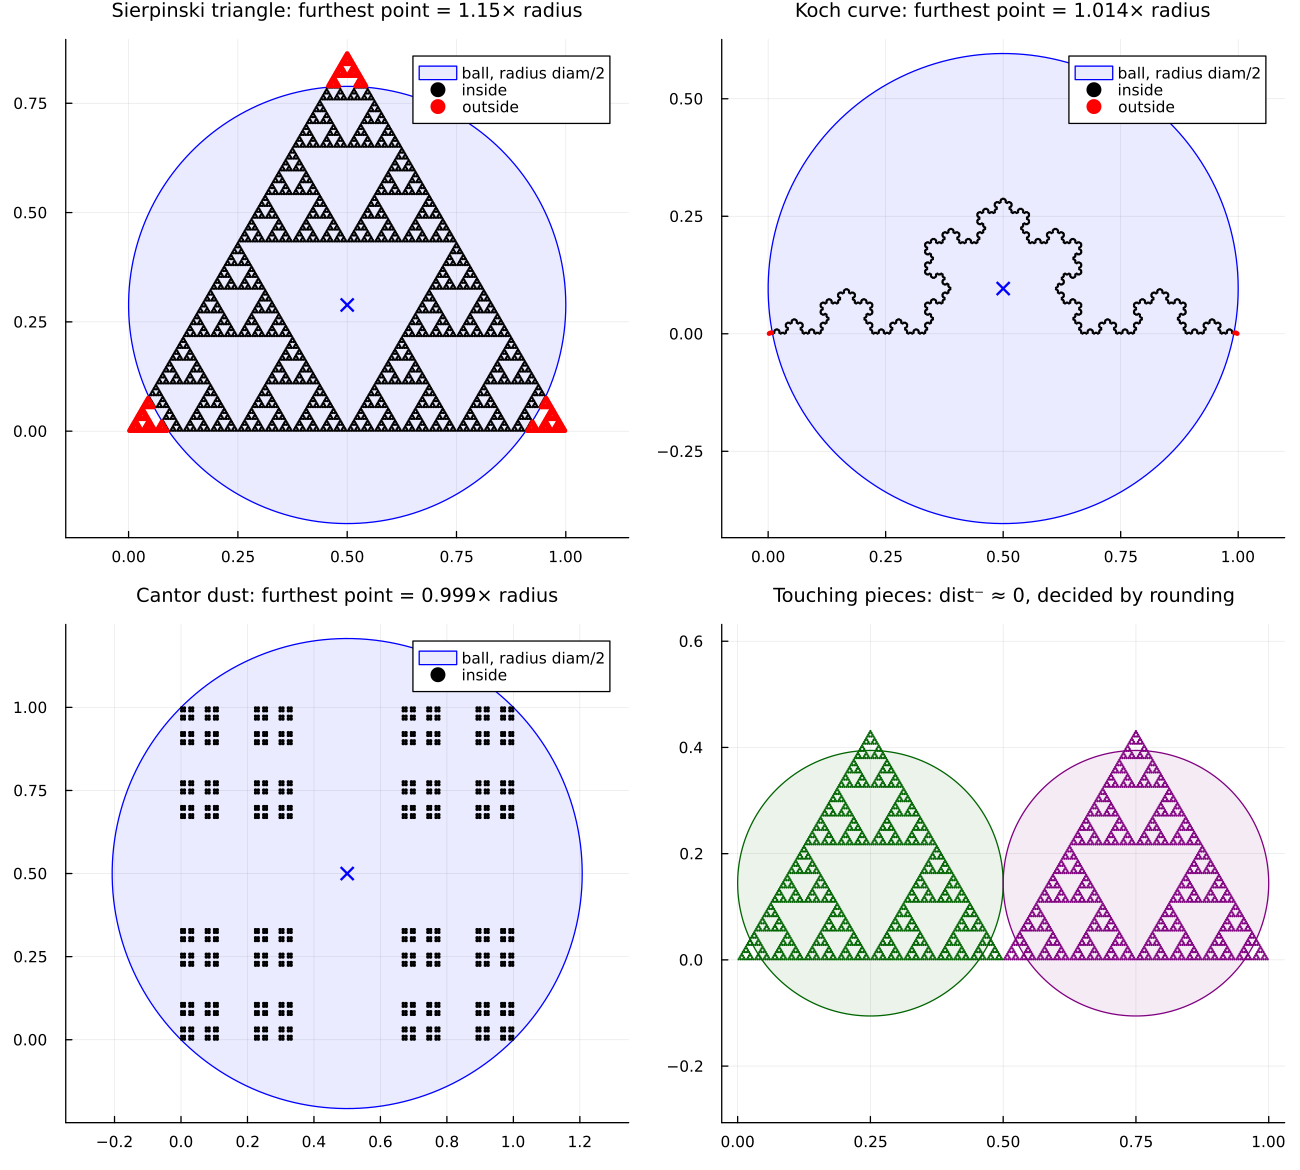

In [5]:
# Sierpinski with the correct dimension (bug 4.1), so that bug doesn't affect this section
sierp = let b = getfractal("sierpinski")
    F.Attractor(collect(b.ifs); d = log(3)/log(2), diam = 1.0,
                connectedness = ones(Bool, 3, 3), symmetries = b.symmetries)
end

fractal_points(Γ, h) = F.barycentre_quadrule(HausdorffMeasure(Γ), h)[1]
ball(c, r) = Shape(c[1] .+ r .* cos.(range(0, 2π, length = 200)), c[2] .+ r .* sin.(range(0, 2π, length = 200)))

function ball_panel(Γ, name; h = 0.005)
    c, r = F.get_boundingball_centre(Γ), F.diam(Γ)/2
    pts = fractal_points(Γ, h)
    out = [norm(p - c) > r for p in pts]
    ratio = maximum(norm(p - c) for p in pts) / r
    p = plot(ball(c, r), fillalpha = 0.08, fillcolor = :blue, linecolor = :blue, label = "ball, radius diam/2",
             aspect_ratio = 1, title = "$name: furthest point = $(round(ratio, digits = 3))× radius", titlefontsize = 10)
    scatter!(p, [q[1] for q in pts[.!out]], [q[2] for q in pts[.!out]], ms = 1, msw = 0, color = :black, label = "inside")
    any(out) && scatter!(p, [q[1] for q in pts[out]], [q[2] for q in pts[out]], ms = 2, msw = 0, color = :red, label = "outside")
    scatter!(p, [c[1]], [c[2]], marker = :x, ms = 5, color = :blue, label = "")
    return p
end

# Two touching sub-triangles: the balls only just touch, so the gap is pure rounding
function touching_panel(Γ)
    a, b = Γ[[1]], Γ[[2]]
    p = plot(aspect_ratio = 1, title = "Touching pieces: dist⁻ ≈ 0, decided by rounding", titlefontsize = 10)
    for (γ, col) in ((a, :darkgreen), (b, :purple))
        c, r = F.get_boundingball_centre(γ), F.diam(γ)/2
        plot!(p, ball(c, r), fillalpha = 0.08, fillcolor = col, linecolor = col, label = "")
        pts = fractal_points(γ, 0.005)
        scatter!(p, [q[1] for q in pts], [q[2] for q in pts], ms = 1, msw = 0, color = col, label = "")
    end
    return p
end

fig = plot(ball_panel(sierp, "Sierpinski triangle"),
           ball_panel(getfractal("kochcurve"), "Koch curve"),
           ball_panel(dust, "Cantor dust"),
           touching_panel(sierp),
           layout = (2, 2), size = (1000, 900), legend = :topright, dpi = 130)
png_path = joinpath(@__DIR__, "bounding_balls.png")
savefig(fig, png_path)
display("image/png", read(png_path))

The ball can miss part of the fractal, and for touching pieces the `dist⁻ <= 0` test comes down to rounding error. The real question is **whether that changes any results**, so I measured it for both places the test is used.

**(a) Galerkin** (`sesquilinearforms.jl:55`). How many touching pairs does the test wrongly call separated, and by how much? A gap of about 1e-15 means rounding, not geometry.

In [6]:
function touching_report(name, Γ, ℓ)
    M = length(Γ.ifs)
    fixed = [F.fixed_point(s) for s in Γ.ifs]
    words = vec([collect(w) for w in Iterators.product(fill(1:M, ℓ)...)])
    corners = [[F.simmulticomp(Γ.ifs, w)(p) for p in fixed] for w in words]
    pieces = [Γ[w] for w in words]
    gaps = Float64[]
    for i in eachindex(words), j in (i+1):length(words)
        if minimum(norm(p - q) for p in corners[i], q in corners[j]) < 1e-10
            push!(gaps, F.dist⁻(pieces[i], pieces[j]) / F.diam(pieces[i]))
        end
    end
    println(rpad(name, 12), "touching pairs: ", rpad(length(gaps), 5), "wrongly separated: ", rpad(count(>(0), gaps), 4), "largest gap/diam: ", maximum(gaps))
end
touching_report("Sierpinski", sierp, 4)
touching_report("Koch curve", getfractal("kochcurve"), 3)
touching_report("Carpet", getfractal("carpet"), 2)
touching_report("Vicsek", getfractal("vicsek"), 2);

Sierpinski  touching pairs: 

120  wrongly separated: 34  largest gap/diam: 4.440892098500626e-16
Koch curve  touching pairs: 

63   wrongly separated: 0   largest gap/diam: 0.0
Carpet      touching pairs: 

156  wrongly separated: 34  largest gap/diam: 1.5897186144173223e-15
Vicsek      touching pairs: 

24   wrongly separated: 11  largest gap/diam: 1.5897186144173223e-15


So the wrong separations are purely rounding, not a real gap. Next I compare the Galerkin solve as it stands with one where `dist⁻` treats these rounding-sized gaps as zero. The next three cells temporarily override `dist⁻` inside this session only, then restore it. `src/` is not changed.

In [7]:
S_sierp = F.singlelayer_operator_helmholtz(HausdorffMeasure(sierp), 5.0)
g(x) = exp(im*5.0*x[1])
θs = range(0, 2π, length = 60)
galerkin_run(h) = (D = F.discretise(S_sierp, h_mesh = h, h_quad = h/8);
                   (D.stiffness_matrix, F.farfield_pattern(D \ g, 5.0).(θs)))
stock = Dict(h => galerkin_run(h) for h in (0.3, 0.15, 0.08));

# Temporary override: rounding-sized gaps count as touching
@eval F dist⁻(Γ::AbstractAttractor, γ::AbstractAttractor) =
    (v = max(dist⁺(Γ, γ) - diam(Γ)/2 - diam(γ)/2, 0.0); v <= 1e-10*min(diam(Γ), diam(γ)) ? 0.0 : v);

In [8]:
for h in (0.3, 0.15, 0.08)
    A, ff = galerkin_run(h)
    A₀, ff₀ = stock[h]
    println("h = $h, N = $(size(A, 1)):  entries changed $(count(abs.(A - A₀) .> 1e-12))/$(length(A)),  ",
            "largest entry change $(round(maximum(abs.(A - A₀) ./ abs.(A)), sigdigits = 2)),  ",
            "far-field change $(round(norm(ff - ff₀, Inf)/norm(ff, Inf), sigdigits = 2))")
end

h = 0.3, N = 9:  entries changed 4/81,  largest entry change 2.6e-6,  

far-field change 4.5e-7
h = 0.15, N = 27:  entries changed 20/729,  largest entry change 1.8e-6,  far-field change 2.4e-7


h = 0.08, N = 81:  entries changed 68/6561,  largest entry change 1.3e-6,  far-field change 1.5e-7


In [9]:
# Restore the original definition
@eval F dist⁻(Γ::AbstractAttractor, γ::AbstractAttractor) = max(dist⁺(Γ, γ) - diam(Γ)/2 - diam(γ)/2, 0.0);

**(b) Collocation** (`collocation.jl:36`). Here the ball can matter: with oversampling, a collocation node can lie on an element but outside its ball, so that entry skips the graded quadrature. This compares the current behaviour with a ball of the true radius for the Sierpinski triangle (`diam/√3`, Laplace, `h_mesh = 0.3`).

In [10]:
S_lap = F.singlelayer_operator_laplace(HausdorffMeasure(sierp))
col_run(hc) = (D = F.discretise(S_lap, h_mesh = 0.3, h_quad = 0.075, h_col = hc, method = :collocation, min_mesh_width_permitted = 1e-3);
               (copy(D.collocation_matrix), (D \ (x -> 1.0 + 0im)).coeffs))
stock_col = Dict(hc => col_run(hc) for hc in (0.3, 0.08, 0.04));

# Temporary override: ball of the true radius for the Sierpinski triangle
@eval F dist⁻(Γ::AbstractAttractor, x) = max(norm(x - get_boundingball_centre(Γ)) - diam(Γ)/sqrt(3), 0.0);

In [11]:
for hc in (0.3, 0.08, 0.04)
    A, c = col_run(hc)
    A₀, c₀ = stock_col[hc]
    println("h_col = $hc:  entries changed $(count(abs.(A - A₀) .> 1e-12))/$(length(A)),  ",
            "largest entry change $(round(maximum(abs.(A - A₀) ./ abs.(A)), sigdigits = 2)),  ",
            "solution change $(round(norm(c - c₀)/norm(c₀), sigdigits = 2))")
end

h_col = 0.3:  entries changed 9/81,  largest entry change 0.0001,  solution change 0.00015


h_col = 0.08:  entries changed 81/729,  largest entry change 6.6e-5,  solution change 9.8e-5


h_col = 0.04:  entries changed 243/2187,  largest entry change 0.0075,  solution change 0.00065


In [12]:
# Restore the original definition
@eval F dist⁻(Γ::AbstractAttractor, x) = max(norm(x - get_boundingball_centre(Γ)) - diam(Γ)/2, 0.0);

**Conclusion.** Andrew's scepticism was largely justified. In the Sierpinski cases measured here, the effect on Galerkin results is about 1e-7, far below discretisation error. For collocation the solution changes by about 0.01% to 0.07%. That's an upper bound on the effect of the ball error: the override also makes the graded meshes finer, which is why entries change even at `h_col = 0.3`, where there's no oversampling.

**Recommendation: don't change this now.** A true fix needs a valid bounding radius, which is the open "bounding ball problem" in `todo.md`, and is a design question rather than a quick fix. H-matrices would rely on these balls for their tree (`next_steps.md`), so it should be solved before that work.

## 4. The other bugs

### 4.1 Wrong Hausdorff dimension in two presets
`compactattractors.jl:97` uses `log(5)` for the Sierpinski triangle, and `:165` uses `log(3)` for the carpet whatever ρ is.

In [13]:
tri = getfractal("sierpinski")
attempt("Sierpinski d (should be log3/log2 = 1.585)", () -> tri.d)
attempt("Sum of its Hausdorff weights (should be 1)", () -> sum(HausdorffMeasure(tri).weights))
attempt("chaos_quadrule on Sierpinski (consequence)", () -> length(F.chaos_quadrule(tri, 1000)[1]))
attempt("Carpet ρ=1/4, d (should be log8/log4 = 1.5)", () -> F.sierpinskicarpet(ρ = 1/4).d)

Sierpinski d (should be log3/log2 = 1.585)       => 2.321928094887362
Sum of its Hausdorff weights (should be 1)       => 

0.6000000000000001
chaos_quadrule on Sierpinski (consequence)       => 

THROWS ArgumentError: reducing over an empty collection is not allowed; consider supplying `init` to the reducer
Carpet ρ=1/4, d (should be log8/log4 = 1.5)      => 1.892789260714372


**This one changes numerical results for every Sierpinski computation**, including the barycentre. The reciprocity test passes anyway.

**Proposed fix:** `log(T(5))` → `log(T(3))`, and `log(T(8))/log(T(3))` → `log(T(8))/log(1/ρ)`.

### 4.2 Fractal block reuse never runs
`matrixreps.jl:108` tests `HausdorffMeasure{<:AbstractHomogenousAttractor}`, but the first type parameter of a measure is `N`, not the attractor. So the test is always false.

In [14]:
V = F.construct_quasiuniform_prebary_p0basis(HausdorffMeasure(dust), 0.2, 0.05)
println("Test as written:           ", V isa F.QuasiUniformBasis{<:HausdorffMeasure{<:F.AbstractHomogenousAttractor}})
println("Test with correct position: ", V isa F.QuasiUniformBasis{<:HausdorffMeasure{<:Any, <:Any, <:Any, <:F.AbstractHomogenousAttractor}})

Test as written:           false
Test with correct position: true


**Don't simply correct the type here.** The cell below applies the reuse pattern to a fully computed matrix, to see what switching it on would do. It's right for non-rotating fractals but **wrong for the Koch curve, which has rotating maps**. (`get_galerkinreps` has an `is_attractor_rotating` check, but both of its branches are identical.)

In [15]:
function reuse_error(name, h)
    Γ = name == "sierpinski" ? sierp : getfractal(name)
    S = F.singlelayer_operator_helmholtz(Γ, 3.0, ambient_dimension = max(F.get_ambient_dimension(Γ), 2))
    A = F.discretise(S, h_mesh = h, h_quad = h/4, reps = false).stiffness_matrix
    N, M = size(A, 1), length(Γ.ifs)
    reps = zeros(Int64, N, N)
    F.symmetricreps!(reps, N)
    F.fractaldiagblocks!(reps, N, M)
    F.cleanreps!(reps)
    B = [reps[i] == 0 ? A[i] : A[reps[i]] for i in eachindex(A)]
    println(rpad(name, 12), "rotating maps: ", rpad(F.is_attractor_rotating(Γ), 7), "entries computed: ", rpad("$(count(==(0), reps))/$(N^2)", 13),
            "matrix error: ", round(norm(B[:] - A[:])/norm(A), sigdigits = 2))
end
for (name, h) in (("cantorset", 0.02), ("cantordust", 0.1), ("sierpinski", 0.1), ("vicsek", 0.1), ("kochcurve", 0.1))
    reuse_error(name, h)
end

cantorset   rotating maps: 

false  entries computed: 51/256       matrix error: 7.5e-17


cantordust  rotating maps: 

false  entries computed: 1117/4096    matrix error: 4.5e-16


sierpinski  rotating maps: 

false  entries computed: 1339/6561    matrix error: 1.7e-6


vicsek      rotating maps: 

false  entries computed: 4671/15625   matrix error: 7.9e-7
kochcurve   rotating maps: true   entries computed: 1117/4096    matrix error: 0.083


**Recommendation: don't fix this in the bug batch.** Move it to `dev-speedup`, enabled only for non-rotating attractors. That's a performance change, and it has its own correctness tests to write. It should cut assembly time noticeably (about 2 to 3× in my quick timing).

### 4.3 Smaller errors, each a one- or two-line fix

In [16]:
μ_dust = HausdorffMeasure(dust)

# barycentrerule.jl:1, same type-parameter mistake as 4.2
attempt("Barycentre rule, non-Hausdorff, homogeneous 2D", () -> length(F.barycentre_quadrule(InvariantMeasure(dust, fill(0.25, 4)), 0.1)[1]))

# measurepresets.jl:17, suppmeasure stays as the type Nothing
attempt("getmeasure on a fractal with unknown measure", () -> typeof(getmeasure("cantordust")).name.name)

# quadrature.jl:55, the todo-list bug: index [0] reaches ifs[0]
attempt("Identity operator, single-element mesh", () -> F.discretise(F.IdentityOperator(dust), h_mesh = 10.0).stiffness_matrix)

# sesquilinearforms.jl:21-22, compares against the element not its index, and then uses the larger measure
V_coarse = F.construct_quasiuniform_prebary_p0basis(μ_dust, 0.3, 0.1)
V_fine = F.construct_quasiuniform_prebary_p0basis(μ_dust, 0.1, 0.05)
a = V_coarse[1]
b = first(e for e in V_fine if Vector(e.vindex)[1:length(a.vindex)] == Vector(a.vindex))
println(rpad("Inner product of nested elements", 48), " => ", dot(a, b), "  (should be ", b.measure.suppmeasure*a.normalisation*b.normalisation, ")")

# unions.jl:22, field doesn't exist
attempt("MeasureUnion ∪ measure", () -> typeof(Base.:∪(μ_dust ∪ μ_dust, μ_dust)).name.name)

# similarities.jl:135, field doesn't exist (function is unused)
attempt("sim_map_inv", () -> F.sim_map_inv(dust.ifs[1], [0.1, 0.1]))

# FractalIntegrals.jl:13, exports a name that doesn't exist
attempt("Is the exported FractaPresets defined?", () -> isdefined(F, :FractaPresets))

# binaryoperators.jl:77, the argument is *named* BlockOperator, so this method applies to every type
foreach(m -> println(rpad("getindex method applying to any type", 48), " => ", m), filter(m -> m.module == F && m.sig == Tuple{typeof(getindex), Any, Vararg{Any}}, methods(getindex)))
attempt("getindex(:a, 1, 2) (should be a MethodError)", () -> getindex(:a, 1, 2))

Barycentre rule, non-Hausdorff, homogeneous 2D   => 

THROWS MethodError: no method matching get_bary_weights(::InvariantMeasure{2, 4, Float64, FractalIntegrals.HomogenousAttractor{2, 4, Float64}}, ::Int64)
The 


┌ Warning: The Hausdorff measure of cantordust is not known. 
│                 Thus, the measure will be scaled by the Hausdorff measure of the attractor. 
│                 Note that this will lead to meaningless results for second-kind integral equations.
└ @ FractalIntegrals ~/Dropbox/unfinished academic projects/FractalIntegrals/src/fractalpresets/measurepresets.jl:22


getmeasure on a fractal with unknown measure     => THROWS MethodError: no method matching Float64(::Type{Nothing})
The type `Float64` exists, but no method is defined for this combination of argument types wh
Identity operator, single-element mesh           => 

THROWS BoundsError: attempt to access NTuple{4, Similarity{2, Float64}} at index [0]
Inner product of nested elements                 => 

0.0  (should be 0.5)
MeasureUnion ∪ measure                          

 => THROWS FieldError: type FractalIntegrals.MeasureUnion has no field `attractors`, available fields: `measures`
sim_map_inv                                      => THROWS FieldError: type Similarity has no field `rA`, available fields: `ρ`, `δ`, `A`, `ρA`
Is the exported FractaPresets defined?           => false
getindex method applying to any type            

 => getindex(BlockOperator, args...) @ FractalIntegrals ~/Dropbox/unfinished academic projects/FractalIntegrals/src/operators/binaryoperators.jl:77
getindex(:a, 1, 2) (should be a MethodError)     => THROWS FieldError: type Symbol has no field `operators`; Symbol has no fields at all.


### 4.4 Documentation and examples (from reading, not run)

- `README.md:12`: `Pkg.install` should be `Pkg.add`.
- `docs/src/integralequations.md:62` and the `SeparableIntegralOperator` docstring (`integraloperators.jl:18`): say `|x-y|^s`, but the code uses `|x-y|^-s`.
- `src/fractalgeometry/attractors.jl:47`: the docstring example `Bool(ones(3,3))` throws. It should be `ones(Bool, 3, 3)`.
- `examples/two_dimensional_scattering.jl:59,124`: uses `Γ.n` and `ϕ`, which don't exist there.

## 5. Outcome (Andrew approved these recommendations on 2026-11-03)

| # | Bug | Change | Recommendation |
|---|---|---|---|
| A | `∪` breaks block operators | 1 line | **Fix** |
| B | 3D Helmholtz operator | 1 line | **Fix**, with a test |
| C | Sierpinski and carpet dimension | 2 lines | **Fix** (changes Sierpinski results) |
| D | Barycentre weights type mistake | 1 line | **Fix** |
| E | `getmeasure` on unknown measure | 1 line | **Fix** |
| F | Identity on single-element mesh | 1 line | **Fix** |
| G | Nested inner product | 2 lines | **Fix** |
| H | `MeasureUnion`, `sim_map_inv`, `FractaPresets` export | 3 lines | **Fix** |
| I | `getindex` applying to every type | 1 line | **Fix** |
| J | Docs and example errors (4.4) | few lines | **Fix**, if you're happy for me to edit these |
| K | Fractal block reuse | | **Defer** to `dev-speedup`, non-rotating only |
| L | Bounding balls | | **Don't fix now**; design question to settle before H-matrices |